# Notebook 2: Vectorization, Modeling & LLM Distillation

Notebook 2 — Vectorization, Modeling & LLM
Distillation
Filename: P3_MovieGenre-2_Modeling_<TeamName>.ipynb
Turn the plot text into features, train a logistic regression classifier for each of your
selected genres, and find out how much accuracy you lose when an LLM supplies the
training labels instead of IMDB.
Every model in this notebook is logistic regression. Holding the classifier
fixed makes the representation the only thing you are comparing, and keeps every
model explainable — on TF-IDF, each coefficient belongs to a word, which
Notebook 3 uses.
One binary classifier per selected genre. A movie can belong to several of
your genres at once, so each genre is its own yes/no problem with its own y. Every
step below that trains or scores a model does it for all 3 selected genres.
Steps 6–8 are knowledge distillation via pseudo-labeling. Pretend you never
had IMDB's genres column for the training set, and instead use an LLM as a teacher
to annotate the training plots, then train a lightweight classical model as a student
on those noisy labels. The student is cheap to run and deployable — the teacher is
expensive and slow. The question is how much accuracy you lose by substituting
an LLM annotator for real ground-truth labels.

## 1. Setup

The only model input is `plot_synopsis`. The IMDB columns (`startYear`, `runtimeMinutes`, `averageRating`, `numVotes`) are used only to filter rows, never as features.

**File locations.** The notebook finds `mpst_imdb_movies.csv` on its own. It checks, in order: the notebook's own folder, the top of the repo, a `msds565_data/` folder next to the repo, and the folder that holds the repo. To keep the CSV somewhere else, set the `MSDS565_DATA` environment variable to that folder before launching Jupyter. The embedding cache (`emb_cache/`), the teacher cache (`teacher_cache.jsonl`) and `pseudo_labeled.csv` are written next to the CSV. None of these files may be committed, so they are listed in the repo's `.gitignore`. `MODELS_DIR` is the repo's top-level `models/` folder.

In [1]:
import os
import warnings
from pathlib import Path

# Keep Hugging Face downloads quiet so the committed notebook has clean output
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, f1_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
warnings.filterwarnings("ignore", category=FutureWarning)

# --- Paths -----------------------------------------------------------------
NOTEBOOK_DIR = Path.cwd()
REPO_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
CSV_NAME = "mpst_imdb_movies.csv"


def find_csv():
    """Return the first copy of the CSV found in the usual places."""
    candidates = [NOTEBOOK_DIR,                        # same folder as the notebook
                  REPO_ROOT,                           # top of the repo
                  REPO_ROOT.parent / "msds565_data",   # data folder next to the repo
                  REPO_ROOT.parent]                    # folder that holds the repo
    if os.environ.get("MSDS565_DATA"):                 # optional override
        candidates.insert(0, Path(os.environ["MSDS565_DATA"]))
    for folder in candidates:
        if (folder / CSV_NAME).exists():
            return folder / CSV_NAME
    raise FileNotFoundError(f"{CSV_NAME} not found. Looked in:\n"
                            + "\n".join(f"  {c}" for c in candidates)
                            + "\nMove the CSV into one of these folders, or set MSDS565_DATA to its folder.")


CSV_PATH = find_csv()
DATA_DIR = CSV_PATH.parent                       # caches and exported CSVs are written next to the CSV
EMB_CACHE_DIR = DATA_DIR / "emb_cache"
MODELS_DIR = REPO_ROOT / "models"                # committed to the repo
print(f"CSV found in: {CSV_PATH.parent.name}/  |  models saved to: {MODELS_DIR.parent.name}/models/")

# --- Settings --------------------------------------------------------------
MIN_VOTES = 100                                  # vote filter chosen in Notebook 1
GENRES = ["Crime", "Action", "Comedy"]
EMB_MODEL_ID = "sentence-transformers/all-MiniLM-L6-v2"
EMB_SHORT = "emb-minilm"                         # used in filenames

RANDOM_STATE = 42
LR_C = 0.1
CLASS_WEIGHTS = [None, "balanced",
                 {0: 1, 1: 2}, {0: 1, 1: 3}, {0: 1, 1: 5}, {0: 1, 1: 10}]

CSV found in: MSDS565- MovieGenre- KIAGJ/  |  models saved to: MSDS565- MovieGenre- KIAGJ/models/


### Load, filter and split

We apply the `numVotes >= 100` filter chosen in Notebook 1. Very obscure movies tend to have thin or unreliable genre tags, and 100 votes removes them without throwing away much data. The training set is MPST's `train` + `val` rows and the test set is its `test` rows. Every model in this notebook is scored on that same test set.

In [2]:
df_all = pd.read_csv(CSV_PATH)                       # unfiltered (used for the embedding cache)
df = df_all[df_all["numVotes"] >= MIN_VOTES].copy()  # filtered

train_df = df[df["split"].isin(["train", "val"])].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

text_train = train_df["plot_synopsis"]
text_test = test_df["plot_synopsis"]

print(f"Vote filter: numVotes >= {MIN_VOTES}")
print(f"Training rows (train+val): {len(train_df)}")
print(f"Test rows:                 {len(test_df)}")


Vote filter: numVotes >= 100
Training rows (train+val): 9365
Test rows:                 2330


## 2. Selected genres

In [3]:
rates = pd.DataFrame({
    "train_positives": train_df[GENRES].sum(),
    "train_rate_%": (100 * train_df[GENRES].mean()).round(1),
    "test_positives": test_df[GENRES].sum(),
    "test_rate_%": (100 * test_df[GENRES].mean()).round(1),
})

too_rare = rates[(rates["train_rate_%"] < 5) | (rates["test_rate_%"] < 5)]
if not too_rare.empty:
    raise ValueError(f"These genres are under 5% positives, pick others:\n{too_rare}")
rates

,train_positives,train_rate_%,test_positives,test_rate_%
Crime,2009,21.5,492,21.1
Action,2078,22.2,540,23.2
Comedy,2853,30.5,680,29.2


We chose **Crime, Action and Comedy** because they are three of our favorite genres to watch, and they also make a good modeling problem:

- **All three clear the 5% minimum easily** (21–30% positives) in both the training and test sets, so each classifier has roughly 2,000+ positive examples to learn from.
- **Crime and Action often overlap** (heists, cops, chases), so these two classifiers have to pick up on fairly subtle differences in the plot text.
- **Comedy is about tone rather than events.** A plot summary describes what happens, not how funny it is, so we expect Comedy to be the hardest of the three to predict from the synopsis.

## 3. Text representations

### TF-IDF

| Setting | Why |
|---|---|
| `stop_words="english"` | Removes filler words ("the", "and") that appear in every plot and carry no genre signal |
| `min_df=5` | Drops words that appear in fewer than 5 synopses, mostly typos and one-off character names |
| `max_features=10000` | Keeps the 10,000 most frequent remaining words, which keeps the model fast and the coefficients readable in Notebook 3 |
| `sublinear_tf=True` | Uses log(1 + count), so a word repeated 30 times in one long synopsis doesn't drown out everything else |

The vectorizer and scaler are fit on the **training set only**. The test set is only transformed, so no test information leaks into the features. `StandardScaler(with_mean=False)` scales each column without centering, which keeps the matrix sparse.

In [4]:
tfidf = TfidfVectorizer(stop_words="english", min_df=5, max_features=10000, sublinear_tf=True)
x_tfidf_train_raw = tfidf.fit_transform(text_train)      # fit on TRAIN only
x_tfidf_test_raw = tfidf.transform(text_test)            # only transform the test set

tfidf_scaler = StandardScaler(with_mean=False)           # with_mean=False keeps it sparse
x_tfidf_train = tfidf_scaler.fit_transform(x_tfidf_train_raw)
x_tfidf_test = tfidf_scaler.transform(x_tfidf_test_raw)

print("TF-IDF train shape:", x_tfidf_train.shape)
print("TF-IDF test shape: ", x_tfidf_test.shape)

TF-IDF train shape: (9365, 10000)
TF-IDF test shape:  (2330, 10000)


### Sentence embeddings

**Model:** `sentence-transformers/all-MiniLM-L6-v2` produces **384-dimensional** vectors.

**Why this model:** It is small (about 22M parameters) and fast, so embedding all ~11,800 synopses is practical even without a GPU. It is also one of the most widely used general-purpose sentence-embedding models, which makes it a sensible baseline to compare against TF-IDF. One limitation: it reads at most 256 word-pieces, so long synopses are effectively truncated to their opening portion.

**Caching:** The embeddings are computed once for every movie in the CSV and saved to `emb_cache/` in the data folder **outside the repo**. Later runs just load the file. Embedding the test plots is not leakage, because the embedding model never sees a label. The `StandardScaler` is still fit on the training rows only.

In [5]:
EMB_CACHE_DIR.mkdir(parents=True, exist_ok=True)
emb_file = EMB_CACHE_DIR / f"{EMB_SHORT}_all_movies.npz"

if emb_file.exists():
    cached = np.load(emb_file, allow_pickle=True)  # older caches stored ids as objects
    emb_ids, emb_all = cached["ids"], cached["emb"]
    print("Loaded cached embeddings:", emb_all.shape)
else:
    from huggingface_hub.utils import logging as hub_logging
    from transformers.utils import logging as tf_logging
    from sentence_transformers import SentenceTransformer
    hub_logging.set_verbosity_error()      # hides the HF_TOKEN warning
    tf_logging.set_verbosity_error()
    tf_logging.disable_progress_bar()      # hides the "Loading weights" bar

    st_model = SentenceTransformer(EMB_MODEL_ID)
    emb_all = st_model.encode(df_all["plot_synopsis"].tolist(),
                              batch_size=32, show_progress_bar=False)
    emb_ids = df_all["imdb_id"].to_numpy(dtype=str)  # plain strings, loadable without pickle
    np.savez(emb_file, ids=emb_ids, emb=emb_all)
    print("Computed and saved embeddings:", emb_all.shape)

print("Embedding dimensionality:", emb_all.shape[1])

# Look up each row of train/test by imdb_id
row_of = pd.Series(np.arange(len(emb_ids)), index=emb_ids)
x_emb_train_raw = emb_all[row_of[train_df["imdb_id"].astype(str)].to_numpy()]
x_emb_test_raw = emb_all[row_of[test_df["imdb_id"].astype(str)].to_numpy()]

emb_scaler = StandardScaler()
x_emb_train = emb_scaler.fit_transform(x_emb_train_raw)  # fit on TRAIN only
x_emb_test = emb_scaler.transform(x_emb_test_raw)

reps = {
    "tfidf": (x_tfidf_train, x_tfidf_test),
    EMB_SHORT: (x_emb_train, x_emb_test),
}

Loaded cached embeddings: (11824, 384)
Embedding dimensionality: 384


## 4. Class-weighted logistic regression

Each genre is roughly 20–30% positive, so an unweighted model leans toward predicting "no". We handle this with **class weights only** (no resampling). `GridSearchCV` tries 6 settings (`None`, `'balanced'`, and positive-class weights of 2, 3, 5 and 10) using 5-fold stratified cross-validation scored by macro-F1. Macro-F1 averages the F1 of both classes, so a model can't score well by ignoring the minority class.

`C=0.1` (fairly strong regularization) is held fixed for every model. TF-IDF has 10,000 features for about 9,400 training rows, so without strong regularization the model would overfit. Keeping `C` fixed also means `class_weight` is the only setting being tuned, as the assignment asks.

In [6]:
def tune_logreg(x_tr, y_tr):
    """Pick the best class_weight with 5-fold stratified CV (macro-F1)."""
    lr = LogisticRegression(C=LR_C, solver="liblinear", max_iter=1000,
                            random_state=RANDOM_STATE)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    grid = GridSearchCV(lr, {"class_weight": CLASS_WEIGHTS},
                        scoring="f1_macro", cv=cv, n_jobs=-1, refit=True)
    grid.fit(x_tr, y_tr)

    res = grid.cv_results_
    cv_table = pd.DataFrame({
        "class_weight": [str(p["class_weight"]) for p in res["params"]],
        "macro-F1 (mean ± std)": [f"{m:.4f} ± {s:.4f}"
                                  for m, s in zip(res["mean_test_score"], res["std_test_score"])],
        "best": ["<-- best" if r == 1 else "" for r in res["rank_test_score"]],
    })
    return grid.best_estimator_, cv_table

models = {}
for rep, (x_tr, x_te) in reps.items():
    for genre in GENRES:
        y_train = train_df[genre].to_numpy()
        model, cv_table = tune_logreg(x_tr, y_train)
        models[(rep, genre)] = model
        print(f"\n=== {rep} | {genre} ===")
        print(cv_table.to_string(index=False))
    


=== tfidf | Crime ===
 class_weight macro-F1 (mean ± std)     best
         None       0.7487 ± 0.0055         
     balanced       0.7543 ± 0.0092 <-- best
 {0: 1, 1: 2}       0.7523 ± 0.0097         
 {0: 1, 1: 3}       0.7518 ± 0.0089         
 {0: 1, 1: 5}       0.7533 ± 0.0095         
{0: 1, 1: 10}       0.7532 ± 0.0101         

=== tfidf | Action ===
 class_weight macro-F1 (mean ± std)     best
         None       0.7637 ± 0.0061         
     balanced       0.7691 ± 0.0086 <-- best
 {0: 1, 1: 2}       0.7665 ± 0.0054         
 {0: 1, 1: 3}       0.7688 ± 0.0075         
 {0: 1, 1: 5}       0.7682 ± 0.0071         
{0: 1, 1: 10}       0.7686 ± 0.0066         

=== tfidf | Comedy ===
 class_weight macro-F1 (mean ± std)     best
         None       0.7394 ± 0.0093         
     balanced       0.7405 ± 0.0116 <-- best
 {0: 1, 1: 2}       0.7400 ± 0.0108         
 {0: 1, 1: 3}       0.7372 ± 0.0077         
 {0: 1, 1: 5}       0.7351 ± 0.0065         
{0: 1, 1: 10}       0.7327 ± 

**What the cross-validation shows:**

- **TF-IDF beats the embeddings for every genre** (about 0.74–0.77 macro-F1 vs. 0.69–0.74). Specific words such as *police*, *murder*, *fight* and *wedding* seem to be stronger genre signals than a single 384-number summary of the whole plot.
- **TF-IDF prefers `'balanced'`**, though the gaps between weighting settings are small (within about 0.01). It is not very sensitive to the weighting.
- **The embedding models prefer light or no weighting** (`{1: 2}` or `None`). Heavy weights hurt them badly. Comedy drops to 0.49 at weight 10, because the model starts labeling almost every movie positive.
- Comedy is the hardest genre for both representations, which matches our expectation that tone is hard to read from a plot summary.

## 5. Test-set evaluation

Each tuned model is now scored **once** on the held-out test set, against the true IMDB labels. Below are a classification report for every representation × genre, then one grid of confusion heatmaps (rows = representation, columns = genre). The test macro-F1 scores are stored in `imdb_scores` for the leaderboard.

=== tfidf | Crime | class_weight=balanced ===
              precision    recall  f1-score   support

   not Crime      0.893     0.902     0.897      1838
       Crime      0.618     0.596     0.607       492

    accuracy                          0.837      2330
   macro avg      0.755     0.749     0.752      2330
weighted avg      0.835     0.837     0.836      2330

=== tfidf | Action | class_weight=balanced ===
              precision    recall  f1-score   support

  not Action      0.906     0.891     0.898      1790
      Action      0.657     0.694     0.675       540

    accuracy                          0.845      2330
   macro avg      0.781     0.792     0.787      2330
weighted avg      0.848     0.845     0.847      2330

=== tfidf | Comedy | class_weight=balanced ===
              precision    recall  f1-score   support

  not Comedy      0.849     0.841     0.845      1650
      Comedy      0.623     0.638     0.630       680

    accuracy                          0.78

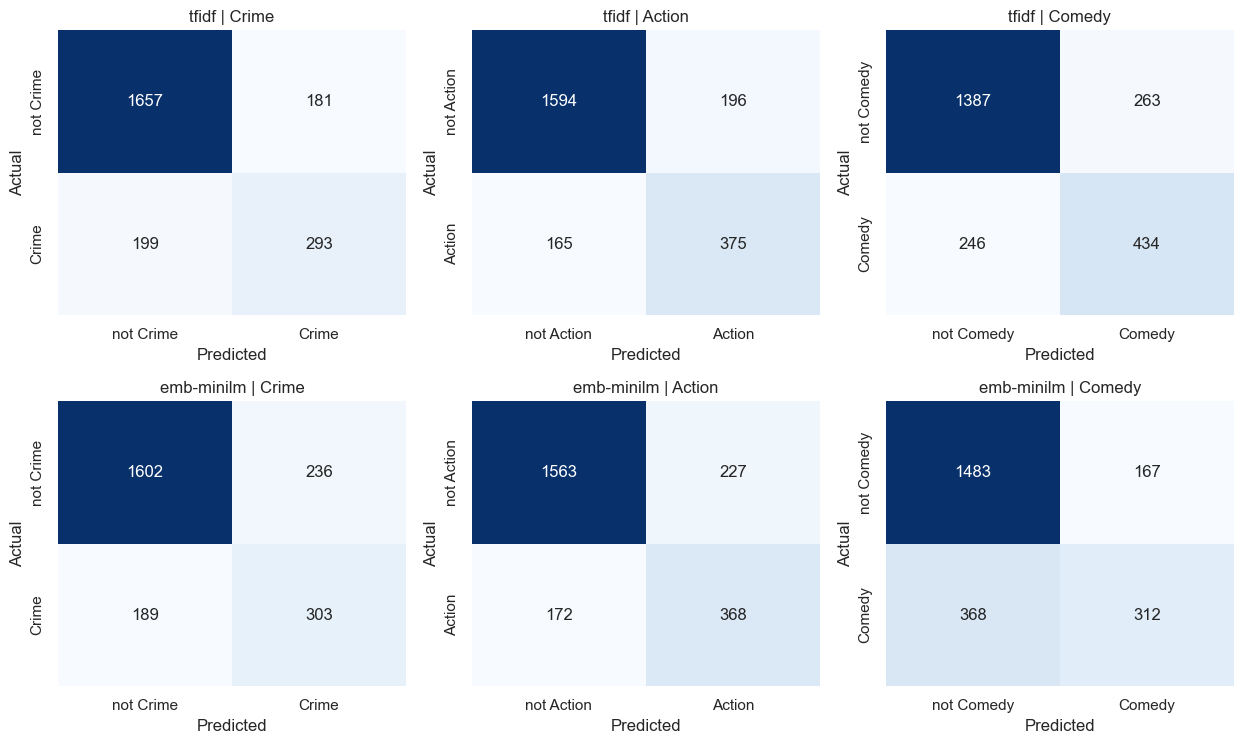

,Crime,Action,Comedy,mean
emb-minilm,0.7353,0.7676,0.6928,0.7319
tfidf,0.7519,0.7867,0.7377,0.7587


In [7]:
fig, axes = plt.subplots(len(reps), len(GENRES),
                         figsize=(4.2 * len(GENRES), 3.8 * len(reps)))
test_f1 = {}

for i, (rep, (_, x_te)) in enumerate(reps.items()):
    for j, genre in enumerate(GENRES):
        model = models[(rep, genre)]
        y_true = test_df[genre].to_numpy()
        y_pred = model.predict(x_te)
        test_f1[(rep, genre)] = f1_score(y_true, y_pred, average="macro")

        labels = [f"not {genre}", genre]
        print(f"=== {rep} | {genre} | class_weight={model.class_weight} ===")
        print(classification_report(y_true, y_pred, target_names=labels, digits=3))

        sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt="d",
                    cmap="Blues", cbar=False, ax=axes[i, j],
                    xticklabels=labels, yticklabels=labels)
        axes[i, j].set(title=f"{rep} | {genre}", xlabel="Predicted", ylabel="Actual")

plt.tight_layout()
plt.show()

imdb_scores = pd.Series(test_f1).unstack()[GENRES]
imdb_scores["mean"] = imdb_scores.mean(axis=1)
imdb_scores.round(4)

## 6. Teacher annotation (pseudo-labeling)

From here on we **pretend we never had IMDB's genre labels** for the training set. An LLM (the *teacher*) labels a small sample of training plots, and in step 8 a logistic regression (the *student*) learns from those labels.

**Teacher:** Google's **`gemini-3.5-flash-lite`** (Gemini 3.5 Flash-Lite), called through the `google-genai` Python SDK (version printed below). We chose it because it runs on the Gemini API's **free tier**, it is a fast, current model, and it supports JSON-schema structured outputs. Classifying a plot into three genres doesn't need a larger model. The API key is read from the `GEMINI_API_KEY` environment variable. If that is missing, the notebook asks for it at a hidden prompt. Either way the key is never printed or saved in the notebook.

**Sample:** For each genre we draw 100 **training-set** movies in that genre (`random_state=42`), combine them and drop duplicates, since a movie can be drawn for two genres. That leaves at most 300 plots. The teacher never sees the test set.

**Prompt rules:**
- **No movie title** is sent, only the plot and the genre names. Otherwise the LLM could recognize the film and recall its genres instead of reading the plot.
- **The reply is enforced with a JSON schema** (`response_mime_type="application/json"` plus `response_json_schema`). There is one required `true`/`false` field per genre and `"additionalProperties": false`, so the model can't skip a genre or invent one. As a second check, the code rejects any reply whose keys aren't exactly the three genres.
- **Truncation:** synopses longer than 10,000 characters (about 2,500 tokens) are cut at the last sentence ending before that limit. This is not because of the context window, which is far larger. The opening of a plot already establishes its genre, and capping the length keeps every request small and predictable.
- **Safety filters** are set to `BLOCK_NONE`. Crime and Action plots routinely describe murders and fights, and a blocked reply would leave a movie without labels. The model is only classifying text, not generating harmful content.

**Unanswered plots:** If Gemini sends back an empty reply three times for the same plot (for example because the prompt was blocked), that movie is recorded as belonging to none of the genres, and the reason is saved in the cache. This counts against the teacher in step 7, which is fair: a real annotator that can't label a movie gives us no usable label. The number of such movies is printed below.

**Rate limits:** The free tier allows only a limited number of requests per minute and per day. The calls are therefore made one at a time with a short pause, and a "too many requests" error (HTTP 429) waits and retries automatically. Labeling ~300 plots takes roughly 15–30 minutes.

**Caching:** Every reply is appended to `teacher_cache_<model>.jsonl` in the data folder (outside the repo) as soon as it arrives. A rerun reuses the saved answers instead of calling the API again, and if a run stops (for example at the daily limit), the next run picks up where it stopped. `pseudo_labeled.csv` is also saved to the data folder, because exported CSVs must not be committed.

In [8]:
import json
import time
from importlib.metadata import version
from google import genai
from google.genai import errors, types

TEACHER_MODEL = "gemini-3.5-flash-lite"
N_PER_GENRE = 100
MAX_CHARS = 10_000
PAUSE_SECONDS = 4                                 # spacing between calls for the free tier
TEACHER_CACHE = DATA_DIR / f"teacher_cache_{TEACHER_MODEL}.jsonl"
PSEUDO_CSV = DATA_DIR / "pseudo_labeled.csv"
KEYS = {g: g.lower() for g in GENRES}             # "Crime" -> "crime"

print(f"Teacher model: {TEACHER_MODEL} | google-genai SDK {version('google-genai')}")

# --- Draw the sample from the TRAINING set only ----------------------------
drawn = [train_df[train_df[g] == 1].sample(N_PER_GENRE, random_state=RANDOM_STATE).index
         for g in GENRES]
sample_idx = pd.Index(np.concatenate(drawn)).unique().sort_values()
sample_df = train_df.loc[sample_idx]
print(f"Drawn: {N_PER_GENRE * len(GENRES)} | unique after dropping duplicates: {len(sample_df)}")
print(f"Synopses truncated to {MAX_CHARS:,} chars: "
      f"{(sample_df['plot_synopsis'].str.len() > MAX_CHARS).sum()}")

Teacher model: gemini-3.5-flash-lite | google-genai SDK 2.10.0
Drawn: 300 | unique after dropping duplicates: 297
Synopses truncated to 10,000 chars: 41


In [9]:
SCHEMA = {
    "type": "object",
    "properties": {k: {"type": "boolean"} for k in KEYS.values()},
    "required": list(KEYS.values()),
    "additionalProperties": False,
}

SYSTEM_PROMPT = (
    "You are a film genre annotator. You will be given the plot synopsis of a movie. "
    "Using only the plot, decide whether the movie belongs to each listed genre. "
    "A movie can belong to several of the genres, exactly one, or none of them. "
    "Judge each genre independently."
)


def truncate(text, max_chars=MAX_CHARS):
    """Cut long plots at the last sentence end before max_chars."""
    if len(text) <= max_chars:
        return text
    cut = text[:max_chars]
    end = cut.rfind(". ")
    return cut[:end + 1] if end > 0.8 * max_chars else cut


def build_prompt(plot):
    # Plot text and genre names only, never the movie title
    return (f"Genres: {', '.join(GENRES)}\n\n"
            f"Plot synopsis:\n{truncate(plot)}\n\n"
            "For each genre, answer true if this movie belongs to it, otherwise false.")


# Use GEMINI_API_KEY if it is set; otherwise ask at a hidden prompt.
# The key is never printed or saved in the notebook.
api_key = os.environ.get("GEMINI_API_KEY", "").strip().strip('"')
if len(api_key) < 30 or "your" in api_key.lower():
    from getpass import getpass
    api_key = getpass("Paste your Gemini API key (it is not saved in the notebook): ").strip().strip('"')
    os.environ["GEMINI_API_KEY"] = api_key
client = genai.Client(api_key=api_key)

CONFIG = types.GenerateContentConfig(
    system_instruction=SYSTEM_PROMPT,
    response_mime_type="application/json",
    response_json_schema=SCHEMA,
    safety_settings=[types.SafetySetting(category=c, threshold="BLOCK_NONE")
                     for c in ["HARM_CATEGORY_HARASSMENT", "HARM_CATEGORY_HATE_SPEECH",
                               "HARM_CATEGORY_SEXUALLY_EXPLICIT", "HARM_CATEGORY_DANGEROUS_CONTENT"]],
)


def reply_problem(response):
    """Explain why Gemini sent back no text (blocked prompt, finish reason, ...)."""
    feedback = getattr(response, "prompt_feedback", None)
    if feedback is not None and getattr(feedback, "block_reason", None):
        return f"prompt blocked ({feedback.block_reason})"
    if response.candidates:
        return f"no text (finish reason: {response.candidates[0].finish_reason})"
    return "no text and no candidates returned"


def ask_teacher(plot, max_tries=6, max_empty=3):
    """One call per movie. Returns (labels, problem).

    Rate limits and temporary server errors wait and retry. If Gemini keeps sending back an
    empty reply, the movie is recorded as belonging to none of the genres and `problem`
    says why, so one unanswerable plot doesn't stop the run.
    """
    empty = 0
    for attempt in range(max_tries):
        try:
            response = client.models.generate_content(
                model=TEACHER_MODEL, contents=build_prompt(plot), config=CONFIG)
        except errors.APIError as e:
            if e.code in (429, 500, 503) and attempt < max_tries - 1:
                wait = min(60, 10 * 2 ** attempt)
                print(f"  HTTP {e.code}, waiting {wait}s and retrying...")
                time.sleep(wait)
                continue
            raise
        if response.text:
            labels = json.loads(response.text)
            if set(labels) != set(KEYS.values()):
                raise RuntimeError(f"Reply has the wrong genres: {labels}")
            return labels, None
        empty += 1
        if empty >= max_empty:
            return {k: False for k in KEYS.values()}, reply_problem(response)
        time.sleep(PAUSE_SECONDS)
    raise RuntimeError(f"No usable reply after {max_tries} tries")

In [10]:
# Load saved answers, then only call the API for movies not yet labeled
cache, unanswered = {}, {}
if TEACHER_CACHE.exists():
    with open(TEACHER_CACHE) as f:
        for line in f:
            rec = json.loads(line)
            cache[rec["imdb_id"]] = rec["labels"]
            if rec.get("problem"):
                unanswered[rec["imdb_id"]] = rec["problem"]

todo = sample_df[~sample_df["imdb_id"].isin(cache)]
print(f"Loaded from cache: {len(sample_df) - len(todo)} | new API calls: {len(todo)}")

# One call at a time; each answer is saved as soon as it arrives.
# Unanswered plots are held back until a good answer follows, so if Gemini fails
# 5 times in a row (a settings problem, not a single odd plot) nothing bad is saved.
pending = []
with open(TEACHER_CACHE, "a") as f:
    for n, (imdb_id, plot) in enumerate(zip(todo["imdb_id"], todo["plot_synopsis"]), start=1):
        labels, problem = ask_teacher(plot)
        record = {"imdb_id": imdb_id, "labels": labels, "problem": problem}
        if problem:
            pending.append(record)
            if len(pending) >= 5:
                raise RuntimeError(f"Gemini sent back no text for 5 plots in a row ({problem}). "
                                   "Check the model name and settings before continuing.")
            continue
        for rec in pending + [record]:
            cache[rec["imdb_id"]] = rec["labels"]
            if rec["problem"]:
                unanswered[rec["imdb_id"]] = rec["problem"]
                print(f"  {rec['imdb_id']}: {rec['problem']} -> recorded as no genre")
            f.write(json.dumps(rec) + "\n")
        f.flush()
        pending = []
        if n % 25 == 0 or n == len(todo):
            print(f"  labeled {n}/{len(todo)}")
        time.sleep(PAUSE_SECONDS)
    for rec in pending:                           # unanswered plots at the very end
        cache[rec["imdb_id"]] = rec["labels"]
        unanswered[rec["imdb_id"]] = rec["problem"]
        f.write(json.dumps(rec) + "\n")

pseudo = sample_df[["imdb_id", "primaryTitle", "plot_synopsis"]].copy()
for genre, key in KEYS.items():
    pseudo[f"pred_{key}"] = [int(cache[i][key]) for i in pseudo["imdb_id"]]

pseudo.to_csv(PSEUDO_CSV, index=False)
print(f"Plots the teacher did not answer (recorded as no genre): {len(unanswered)}")
print(f"Saved {PSEUDO_CSV.name}: {pseudo.shape}")
pseudo.drop(columns="plot_synopsis").head()

Loaded from cache: 0 | new API calls: 297
  tt0409904: prompt blocked (BlockedReason.PROHIBITED_CONTENT) -> recorded as no genre
  tt0086896: prompt blocked (BlockedReason.PROHIBITED_CONTENT) -> recorded as no genre
  labeled 25/297
  HTTP 429, waiting 10s and retrying...
  tt1711425: prompt blocked (BlockedReason.PROHIBITED_CONTENT) -> recorded as no genre
  tt3605418: prompt blocked (BlockedReason.PROHIBITED_CONTENT) -> recorded as no genre
  HTTP 503, waiting 10s and retrying...
  labeled 50/297
  HTTP 503, waiting 10s and retrying...
  labeled 75/297
  tt0055452: prompt blocked (BlockedReason.PROHIBITED_CONTENT) -> recorded as no genre
  labeled 100/297
  tt0133412: prompt blocked (BlockedReason.PROHIBITED_CONTENT) -> recorded as no genre
  labeled 125/297
  HTTP 503, waiting 10s and retrying...
  labeled 150/297
  HTTP 503, waiting 10s and retrying...
  tt2751310: prompt blocked (BlockedReason.PROHIBITED_CONTENT) -> recorded as no genre
  labeled 175/297
  tt0071249: prompt blocke

,imdb_id,primaryTitle,pred_crime,pred_action,pred_comedy
113,tt0409904,Day Watch,0,0,0
123,tt0057012,Dr. Strangelove or: How I Learned to Stop Worr...,0,1,1
130,tt0293662,The Transporter,1,1,0
210,tt1489889,Central Intelligence,1,1,1
222,tt1337032,Trailer Park Boys: Countdown to Liquor Day,1,0,1


## 7. Teacher accuracy

We compare the teacher's labels with the true IMDB labels across the whole sample. **Caveat:** the sample was drawn so that every movie is positive for at least one genre, so it contains far more positives than the full dataset does. Precision here therefore looks better than it would on a random sample of movies.

In [11]:
from sklearn.metrics import precision_recall_fscore_support

rows = []
for genre, key in KEYS.items():
    y_true = sample_df[genre].to_numpy()
    y_pred = pseudo[f"pred_{key}"].to_numpy()
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", zero_division=0)
    rows.append({"genre": genre, "IMDB positives": y_true.sum(), "teacher positives": y_pred.sum(),
                 "precision": p, "recall": r, "F1": f,
                 "macro-F1": f1_score(y_true, y_pred, average="macro")})

teacher_acc = pd.DataFrame(rows).set_index("genre").round(3)
teacher_acc

,IMDB positives,teacher positives,precision,recall,F1,macro-F1
genre,,,,,,
Crime,147,186,0.720,0.912,0.805,0.778
Action,148,182,0.714,0.878,0.788,0.761
Comedy,138,102,0.931,0.688,0.792,0.825


### Where the teacher went wrong

Because the sample is small, we can read the teacher's mistakes directly. The table below shows two false positives and two false negatives per genre, with the start of each plot. The title is shown here for our reference only; the teacher never saw it.

In [12]:
examples = []
for genre, key in KEYS.items():
    y_true = sample_df[genre].to_numpy()
    y_pred = pseudo[f"pred_{key}"].to_numpy()
    for kind, mask in [("false positive", (y_pred == 1) & (y_true == 0)),
                       ("false negative", (y_pred == 0) & (y_true == 1))]:
        for _, row in sample_df[mask].head(2).iterrows():
            examples.append({"genre": genre, "error": kind, "errors of this type": mask.sum(),
                             "title": row["primaryTitle"],
                             "plot (start)": row["plot_synopsis"][:160] + "..."})

pd.DataFrame(examples)

,genre,error,errors of this type,title,plot (start)
0,Crime,false positive,52,A Man Called Blade,Bounty hunter Blade and his prisoner Burt Crav...
1,Crime,false positive,52,Mad Max Beyond Thunderdome,The film opens with an aerial view of a desert...
2,Crime,false negative,13,Angel,The movie opens with 15 year-old honor student...
3,Crime,false negative,13,Knock Knock,Architect and happily married man Evan Webber ...
4,Action,false positive,52,Dr. Strangelove or: How I Learned to Stop Worr...,At the Burpelson U.S. Air Force Base somewhere...
5,Action,false positive,52,We're the Millers,David Clarke (Jason Sudeikis) is sitting on hi...
6,Action,false negative,18,Day Watch,"MOSCOW, January 2006. It is the day after New ..."
7,Action,false negative,18,Angel,The movie opens with 15 year-old honor student...
8,Comedy,false positive,7,The Fifth Element,The story's premise is that every five thousan...
9,Comedy,false positive,7,Lethal Weapon 3,Martin Riggs (Mel Gibson) and Roger Murtaugh (...


## 8. Training on pseudo-labels

We repeat step 4 (the same `GridSearchCV` over `class_weight`, 5-fold stratified CV, macro-F1) for both representations, but only on the sampled movies and with the **teacher's labels** (`pred_<genre>`) as `y`. The features are rows of the matrices from step 3, so the vectorizer and scalers are reused exactly as fitted. They never saw a label, so reusing them doesn't leak anything. Each student is then scored on the full test set against the **true** IMDB labels.

**Control:** The LLM-labeled students differ from the step 4 models in two ways at once: they have noisier labels, and they have far fewer training rows (~300 vs. ~9,400). To separate the two effects, we also train the same models on the same sample with the **true** IMDB labels. That control is not required by the assignment, but it lets the leaderboard show how much of the loss comes from each cause.

In [13]:
x_rows = sample_df.index.to_numpy()          # positions of the sampled movies in train_df
llm_f1, control_f1 = {}, {}

for rep, (x_tr, x_te) in reps.items():
    for genre, key in KEYS.items():
        y_test = test_df[genre].to_numpy()

        # Student trained on the teacher's labels
        model, cv_table = tune_logreg(x_tr[x_rows], pseudo[f"pred_{key}"].to_numpy())
        llm_f1[(rep, genre)] = f1_score(y_test, model.predict(x_te), average="macro")
        print(f"\n=== {rep} | {genre} | LLM labels ===")
        print(cv_table.to_string(index=False))

        # Control: same rows, true IMDB labels
        control, _ = tune_logreg(x_tr[x_rows], sample_df[genre].to_numpy())
        control_f1[(rep, genre)] = f1_score(y_test, control.predict(x_te), average="macro")


=== tfidf | Crime | LLM labels ===
 class_weight macro-F1 (mean ± std)     best
         None       0.6603 ± 0.0547         
     balanced       0.6775 ± 0.0396 <-- best
 {0: 1, 1: 2}       0.6220 ± 0.0455         
 {0: 1, 1: 3}       0.6128 ± 0.0470         
 {0: 1, 1: 5}       0.5839 ± 0.0572         
{0: 1, 1: 10}       0.5563 ± 0.0889         

=== tfidf | Action | LLM labels ===
 class_weight macro-F1 (mean ± std)     best
         None       0.7219 ± 0.0634         
     balanced       0.7435 ± 0.0604 <-- best
 {0: 1, 1: 2}       0.6726 ± 0.0565         
 {0: 1, 1: 3}       0.6689 ± 0.0624         
 {0: 1, 1: 5}       0.6477 ± 0.0504         
{0: 1, 1: 10}       0.6340 ± 0.0475         

=== tfidf | Comedy | LLM labels ===
 class_weight macro-F1 (mean ± std)     best
         None       0.5535 ± 0.0478         
     balanced       0.5792 ± 0.0679         
 {0: 1, 1: 2}       0.5792 ± 0.0679         
 {0: 1, 1: 3}       0.5832 ± 0.0641         
 {0: 1, 1: 5}       0.6175 ± 0.0461

## 9. Leaderboard

Every row except the last is test-set macro-F1 on the held-out test set. The last row is the teacher's macro-F1 **on the training sample it labeled. It was not measured on the test set**, so it is only a rough reference point.

In [14]:
def leaderboard_rows(f1_dict, labels, n_train):
    table = pd.Series(f1_dict).unstack()[GENRES]
    return [{"model": f"{rep} | {labels}", "train rows": n_train, **table.loc[rep].to_dict()}
            for rep in table.index]

board = pd.DataFrame(
    leaderboard_rows(test_f1, "IMDB labels", len(train_df))
    + leaderboard_rows(llm_f1, "LLM labels", len(sample_df))
    + leaderboard_rows(control_f1, "IMDB labels, sample only (control)", len(sample_df))
)
board["mean"] = board[GENRES].mean(axis=1)
board = board.sort_values("mean", ascending=False)

teacher_row = {"model": f"REFERENCE: teacher {TEACHER_MODEL} (training sample, NOT test set)",
               "train rows": np.nan, **teacher_acc["macro-F1"].to_dict()}
teacher_row["mean"] = np.mean([teacher_row[g] for g in GENRES])
board = pd.concat([board, pd.DataFrame([teacher_row])]).set_index("model")

board.round(4)

,train rows,Crime,Action,Comedy,mean
model,,,,,
tfidf | IMDB labels,9365.0,0.7519,0.7867,0.7377,0.7587
emb-minilm | IMDB labels,9365.0,0.7353,0.7676,0.6928,0.7319
"tfidf | IMDB labels, sample only (control)",297.0,0.6856,0.7064,0.6174,0.6698
emb-minilm | LLM labels,297.0,0.5970,0.6319,0.5803,0.6031
"emb-minilm | IMDB labels, sample only (control)",297.0,0.5940,0.6352,0.5658,0.5984
tfidf | LLM labels,297.0,0.5294,0.5782,0.6871,0.5982
"REFERENCE: teacher gemini-3.5-flash-lite (training sample, NOT test set)",NaN,0.7780,0.7610,0.8250,0.7880


In [15]:
mean_f1 = board["mean"]
for rep in reps:
    full = mean_f1[f"{rep} | IMDB labels"]
    llm = mean_f1[f"{rep} | LLM labels"]
    ctrl = mean_f1[f"{rep} | IMDB labels, sample only (control)"]
    print(f"{rep:>11}: total loss {full - llm:.3f} macro-F1 "
          f"= fewer rows {full - ctrl:.3f} + noisier labels {ctrl - llm:.3f}")

      tfidf: total loss 0.161 macro-F1 = fewer rows 0.089 + noisier labels 0.072
 emb-minilm: total loss 0.129 macro-F1 = fewer rows 0.134 + noisier labels -0.005


### Discussion

> **Write this after running the notebook, using the numbers above.** Answer these points and delete this note:
>
> 1. **How much accuracy was lost?** For each representation, compare the mean test macro-F1 of the IMDB-label model with the LLM-label model, using the "total loss" line above.
> 2. **Why?** Split that loss with the control rows: how much comes from training on ~300 rows instead of ~9,400, and how much from the teacher's label mistakes?
> 3. **Which genre suffered most?** Connect it to the teacher's precision and recall in step 7 and to the error examples (for example, did the teacher over-call Action, or miss comedies whose plots don't sound funny?).
> 4. **Was it worth it?** About 300 cheap API calls produced a deployable student model. Is the accuracy given up acceptable compared with paying people to label thousands of movies?

## 10. Export

Notebook 3 explains the TF-IDF models, so it needs the exact fitted objects from this notebook, not refits. We save every model trained on the IMDB labels to the repo's top-level `models/` folder as `P3_N2_<rep>_logreg_<genre>.pkl`, along with the fitted `TfidfVectorizer` and its `StandardScaler`. Without those two, Notebook 3 could not rebuild the features the TF-IDF models were trained on.

In [16]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)

for (rep, genre), model in models.items():
    joblib.dump(model, MODELS_DIR / f"P3_N2_{rep}_logreg_{genre.lower()}.pkl")
joblib.dump(tfidf, MODELS_DIR / "P3_N2_tfidf_vectorizer.pkl")
joblib.dump(tfidf_scaler, MODELS_DIR / "P3_N2_tfidf_scaler.pkl")

sorted(p.name for p in MODELS_DIR.glob("P3_N2_*.pkl"))

['P3_N2_emb-minilm_logreg_action.pkl',
 'P3_N2_emb-minilm_logreg_comedy.pkl',
 'P3_N2_emb-minilm_logreg_crime.pkl',
 'P3_N2_tfidf_logreg_action.pkl',
 'P3_N2_tfidf_logreg_comedy.pkl',
 'P3_N2_tfidf_logreg_crime.pkl',
 'P3_N2_tfidf_scaler.pkl',
 'P3_N2_tfidf_vectorizer.pkl']